In [3]:

print("Colab is working!")


Colab is working!


In [5]:

import os

print(os.listdir('/content'))


['.config', 'Banglore_traffic_Dataset.csv', 'sample_data']


In [6]:

import pandas as pd

file_path = "/content/Banglore_traffic_Dataset.csv"

df = pd.read_csv(file_path, nrows=5)

print("First 5 rows:")
display(df)

print("\nColumn names:")
print(df.columns.tolist())


First 5 rows:


,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No



Column names:
['Date', 'Area Name', 'Road/Intersection Name', 'Traffic Volume', 'Average Speed', 'Travel Time Index', 'Congestion Level', 'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact', 'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage', 'Pedestrian and Cyclist Count', 'Weather Conditions', 'Roadwork and Construction Activity']


In [7]:

import pandas as pd
import os

file_path = "/content/Banglore_traffic_Dataset.csv"

print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
print("Reading complete dataset...")

df = pd.read_csv(file_path, low_memory=False)

print("\nDataset loaded successfully!")
print("Total rows and columns:", df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nData types:")
print(df.dtypes)


File size: 1499.47 KB
Reading complete dataset...

Dataset loaded successfully!
Total rows and columns: (8936, 16)

Missing values:
Date                                  0
Area Name                             0
Road/Intersection Name                0
Traffic Volume                        0
Average Speed                         0
Travel Time Index                     0
Congestion Level                      0
Road Capacity Utilization             0
Incident Reports                      0
Environmental Impact                  0
Public Transport Usage                0
Traffic Signal Compliance             0
Parking Usage                         0
Pedestrian and Cyclist Count          0
Weather Conditions                    0
Roadwork and Construction Activity    0
dtype: int64

Data types:
Date                                   object
Area Name                              object
Road/Intersection Name                 object
Traffic Volume                          int64
Average Speed     

In [9]:

# 1. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 2. Convert Date into proper date format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("\nInvalid dates:", df["Date"].isna().sum())

# 3. Check date range
print("\nEarliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

# 4. Check unique areas and roads
print("\nNumber of unique areas:", df["Area Name"].nunique())
print("Number of unique roads:", df["Road/Intersection Name"].nunique())

print("\nArea names:")
print(df["Area Name"].unique())


Duplicate rows: 0

Invalid dates: 0

Earliest date: 2022-01-01 00:00:00
Latest date: 2024-08-09 00:00:00

Number of unique areas: 8
Number of unique roads: 16

Area names:
['Indiranagar' 'Whitefield' 'Koramangala' 'M.G. Road' 'Jayanagar' 'Hebbal'
 'Yeshwanthpur' 'Electronic City']


In [10]:

# Check numeric columns
print("NUMERIC VALUE CHECK")
print(df.describe().round(2))

# Check negative values
numeric_cols = df.select_dtypes(include="number").columns

print("\nNEGATIVE VALUES")
for col in numeric_cols:
    print(col, ":", (df[col] < 0).sum())

# Check category values
print("\nWEATHER CONDITIONS")
print(df["Weather Conditions"].value_counts())

print("\nROADWORK STATUS")
print(df["Roadwork and Construction Activity"].value_counts())



NUMERIC VALUE CHECK
                                Date  Traffic Volume  Average Speed  \
count                           8936         8936.00        8936.00   
mean   2023-04-22 05:25:11.548791552        29236.05          39.45   
min              2022-01-01 00:00:00         4233.00          20.00   
25%              2022-08-26 00:00:00        19413.00          31.78   
50%              2023-04-24 00:00:00        27600.00          39.20   
75%              2023-12-17 06:00:00        38058.50          46.64   
max              2024-08-09 00:00:00        72039.00          89.79   
std                              NaN        13001.81          10.71   

       Travel Time Index  Congestion Level  Road Capacity Utilization  \
count            8936.00           8936.00                    8936.00   
mean                1.38             80.82                      92.03   
min                 1.00              5.16                      18.74   
25%                 1.24             64.29      

In [11]:

# Create a separate cleaned dataset
clean_df = df.copy()

# Ensure correct date format
clean_df["Date"] = pd.to_datetime(clean_df["Date"])

# Remove unnecessary spaces from text columns
text_cols = clean_df.select_dtypes(include="object").columns

for col in text_cols:
    clean_df[col] = clean_df[col].str.strip()

# Save cleaned dataset
clean_df.to_csv(
    "/content/Bengaluru_Traffic_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Rows and columns:", clean_df.shape)
print("Missing values:", clean_df.isna().sum().sum())
print("Duplicate rows:", clean_df.duplicated().sum())


Cleaned dataset saved successfully!
Rows and columns: (8936, 16)
Missing values: 0
Duplicate rows: 0


In [12]:

# Area-wise traffic analysis

area_analysis = clean_df.groupby("Area Name").agg(
    Total_Records=("Area Name", "size"),
    Number_of_Roads=("Road/Intersection Name", "nunique"),
    Avg_Traffic_Volume=("Traffic Volume", "mean"),
    Avg_Speed=("Average Speed", "mean"),
    Avg_Congestion=("Congestion Level", "mean"),
    Avg_Capacity_Utilization=("Road Capacity Utilization", "mean"),
    Avg_Incidents=("Incident Reports", "mean")
).round(2)

# Sort areas by average congestion
area_analysis = area_analysis.sort_values(
    by="Avg_Congestion",
    ascending=False
)

print("AREA-WISE TRAFFIC ANALYSIS")
display(area_analysis)

# Save results
area_analysis.to_csv(
    "/content/Area_Wise_Traffic_Analysis.csv"
)

print("Area-wise analysis saved successfully!")


AREA-WISE TRAFFIC ANALYSIS


,Total_Records,Number_of_Roads,Avg_Traffic_Volume,Avg_Speed,Avg_Congestion,Avg_Capacity_Utilization,Avg_Incidents
Area Name,,,,,,,
Koramangala,1364,2,40832.25,36.06,93.99,97.43,1.85
M.G. Road,1501,2,35300.43,37.54,90.58,96.55,1.86
Indiranagar,1720,2,32284.39,38.64,87.64,95.76,1.78
Hebbal,950,2,26533.23,40.15,80.09,92.72,1.57
Jayanagar,1173,2,24601.33,39.79,77.00,91.52,1.48
Whitefield,942,2,21295.13,42.14,69.05,86.88,1.28
Yeshwanthpur,734,2,18931.55,43.45,62.37,82.40,1.08
Electronic City,552,2,16346.64,43.66,54.45,76.26,0.78


Area-wise analysis saved successfully!


In [13]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Select features for clustering
features = [
    "Avg_Traffic_Volume",
    "Avg_Speed",
    "Avg_Congestion",
    "Avg_Capacity_Utilization",
    "Avg_Incidents"
]

X = area_analysis[features].copy()

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Test different numbers of clusters
scores = []

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    scores.append((k, round(score, 3)))

print("SILHOUETTE SCORES")
for k, score in scores:
    print(f"Clusters: {k}, Score: {score}")

# Select the best tested cluster count
best_k = max(scores, key=lambda x: x[1])[0]
print("\nSelected number of clusters:", best_k)

# Train final model
final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

area_analysis["Cluster"] = final_model.fit_predict(X_scaled)

# Show cluster assignments
print("\nAREA CLUSTER ASSIGNMENTS")
display(area_analysis[features + ["Cluster"]])

# Cluster profiles
cluster_profile = area_analysis.groupby("Cluster")[features].mean().round(2)

print("\nCLUSTER PROFILES")
display(cluster_profile)


SILHOUETTE SCORES
Clusters: 2, Score: 0.551
Clusters: 3, Score: 0.489
Clusters: 4, Score: 0.429
Clusters: 5, Score: 0.349

Selected number of clusters: 2

AREA CLUSTER ASSIGNMENTS


,Avg_Traffic_Volume,Avg_Speed,Avg_Congestion,Avg_Capacity_Utilization,Avg_Incidents,Cluster
Area Name,,,,,,
Koramangala,40832.25,36.06,93.99,97.43,1.85,0
M.G. Road,35300.43,37.54,90.58,96.55,1.86,0
Indiranagar,32284.39,38.64,87.64,95.76,1.78,0
Hebbal,26533.23,40.15,80.09,92.72,1.57,0
Jayanagar,24601.33,39.79,77.00,91.52,1.48,0
Whitefield,21295.13,42.14,69.05,86.88,1.28,1
Yeshwanthpur,18931.55,43.45,62.37,82.40,1.08,1
Electronic City,16346.64,43.66,54.45,76.26,0.78,1



CLUSTER PROFILES


,Avg_Traffic_Volume,Avg_Speed,Avg_Congestion,Avg_Capacity_Utilization,Avg_Incidents
Cluster,,,,,
0,31910.33,38.44,85.86,94.80,1.71
1,18857.77,43.08,61.96,81.85,1.05


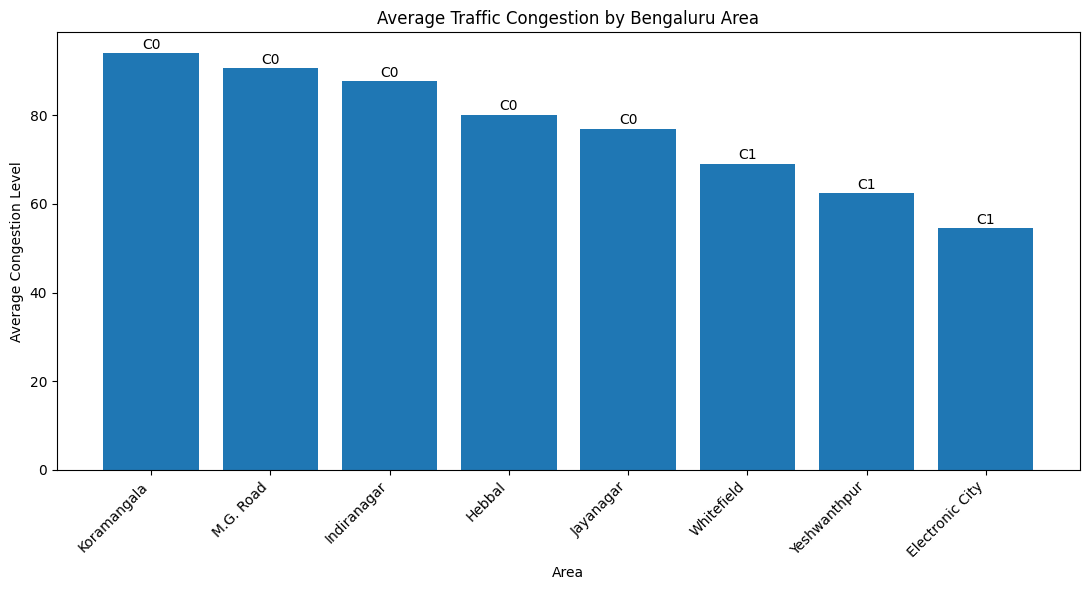

Chart and cluster results saved successfully!


In [14]:

import matplotlib.pyplot as plt

# Create a readable area-wise congestion chart
plot_df = area_analysis.sort_values(
    "Avg_Congestion",
    ascending=False
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    plot_df.index,
    plot_df["Avg_Congestion"]
)

plt.title("Average Traffic Congestion by Bengaluru Area")
plt.xlabel("Area")
plt.ylabel("Average Congestion Level")
plt.xticks(rotation=45, ha="right")

for bar, cluster in zip(bars, plot_df["Cluster"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"C{cluster}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "/content/Bengaluru_Area_Congestion.png",
    dpi=300
)
plt.show()

# Save final cluster results
area_analysis.to_csv(
    "/content/Bengaluru_Traffic_Cluster_Results.csv"
)

print("Chart and cluster results saved successfully!")


In [ ]:
# Bengaluru Traffic Pulse
## Data Cleaning and Exploratory Data Analysis

This notebook performs:
1. Dataset loading
2. Dataset inspection
3. Data quality checks
4. Data cleaning
5. Descriptive statistics
6. Area-wise traffic analysis
7. Data visualisation

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [17]:
df = pd.read_csv(
    "/content/Banglore_traffic_Dataset.csv",
    low_memory=False
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully
Dataset shape: (8936, 16)


,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


In [18]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset columns:
['Date', 'Area Name', 'Road/Intersection Name', 'Traffic Volume', 'Average Speed', 'Travel Time Index', 'Congestion Level', 'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact', 'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage', 'Pedestrian and Cyclist Count', 'Weather Conditions', 'Roadwork and Construction Activity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8936 entries, 0 to 8935
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Date                                8936 non-null   object 
 1   Area Name                           8936 non-null   object 
 2   Road/Intersection Name              8936 non-null   object 
 3   Traffic Volume                      8936 non-null   int64  
 4   Average Speed                       8936 non-null   float64
 5   Travel Time Index                

,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count
count,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000
mean,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348
std,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573
min,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000
25%,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000
50%,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000
75%,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000
max,72039.000000,89.790843,1.500000,100.000000,100.000000,10.000000,194.078000,79.979744,99.993652,99.995049,243.000000


In [19]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nTotal rows:", len(df))

Missing values:


,0
Date,0
Area Name,0
Road/Intersection Name,0
Traffic Volume,0
Average Speed,0
Travel Time Index,0
Congestion Level,0
Road Capacity Utilization,0
Incident Reports,0
Environmental Impact,0



Duplicate records:
0

Total rows: 8936


In [20]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print("Invalid dates:", df["Date"].isnull().sum())

print("Minimum date:", df["Date"].min())
print("Maximum date:", df["Date"].max())

Invalid dates: 0
Minimum date: 2022-01-01 00:00:00
Maximum date: 2024-08-09 00:00:00


In [22]:
numeric_columns = df.select_dtypes(
    include="number"
).columns

negative_values = (df[numeric_columns] < 0).sum()

display(negative_values)

,0
Traffic Volume,0
Average Speed,0
Travel Time Index,0
Congestion Level,0
Road Capacity Utilization,0
Incident Reports,0
Environmental Impact,0
Public Transport Usage,0
Traffic Signal Compliance,0
Parking Usage,0


In [23]:
clean_df = df.copy()

text_columns = clean_df.select_dtypes(
    include="object"
).columns

for column in text_columns:
    clean_df[column] = clean_df[column].str.strip()

clean_df.to_csv(
    "/content/Bengaluru_Traffic_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully")
print("Final shape:", clean_df.shape)
print("Missing values:", clean_df.isnull().sum().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

Cleaned dataset saved successfully
Final shape: (8936, 16)
Missing values: 0
Duplicate rows: 0


In [24]:
area_analysis = clean_df.groupby("Area Name").agg(
    Total_Records=("Area Name", "size"),
    Number_of_Roads=("Road/Intersection Name", "nunique"),
    Avg_Traffic_Volume=("Traffic Volume", "mean"),
    Avg_Speed=("Average Speed", "mean"),
    Avg_Congestion=("Congestion Level", "mean"),
    Avg_Capacity_Utilization=(
        "Road Capacity Utilization", "mean"
    ),
    Avg_Incidents=("Incident Reports", "mean")
).round(2)

area_analysis = area_analysis.sort_values(
    by="Avg_Congestion",
    ascending=False
)

display(area_analysis)

area_analysis.to_csv(
    "/content/Area_Wise_Traffic_Analysis.csv"
)

print("Area-wise analysis saved")

,Total_Records,Number_of_Roads,Avg_Traffic_Volume,Avg_Speed,Avg_Congestion,Avg_Capacity_Utilization,Avg_Incidents
Area Name,,,,,,,
Koramangala,1364,2,40832.25,36.06,93.99,97.43,1.85
M.G. Road,1501,2,35300.43,37.54,90.58,96.55,1.86
Indiranagar,1720,2,32284.39,38.64,87.64,95.76,1.78
Hebbal,950,2,26533.23,40.15,80.09,92.72,1.57
Jayanagar,1173,2,24601.33,39.79,77.00,91.52,1.48
Whitefield,942,2,21295.13,42.14,69.05,86.88,1.28
Yeshwanthpur,734,2,18931.55,43.45,62.37,82.40,1.08
Electronic City,552,2,16346.64,43.66,54.45,76.26,0.78


Area-wise analysis saved


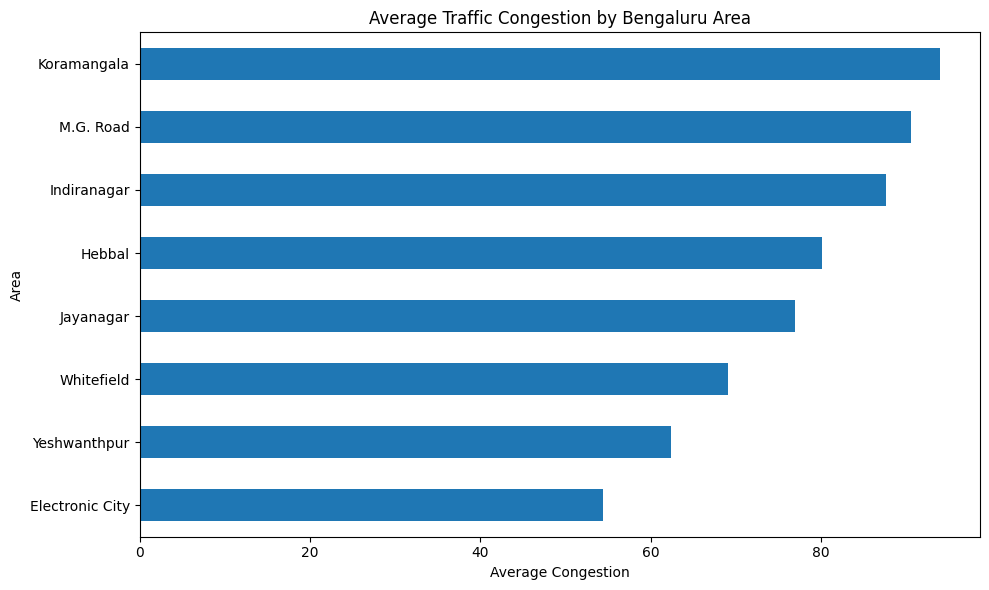

In [25]:
plt.figure(figsize=(10, 6))

area_analysis["Avg_Congestion"].sort_values().plot(
    kind="barh"
)

plt.title("Average Traffic Congestion by Bengaluru Area")
plt.xlabel("Average Congestion")
plt.ylabel("Area")

plt.tight_layout()

plt.savefig(
    "/content/Bengaluru_Area_Congestion.png"
)

plt.show()

In [26]:
print("PROJECT FINDINGS")

print("\nHighest congestion area:")
print(area_analysis["Avg_Congestion"].idxmax())

print("\nLowest congestion area:")
print(area_analysis["Avg_Congestion"].idxmin())

print("\nArea-wise traffic analysis:")
display(area_analysis)

PROJECT FINDINGS

Highest congestion area:
Koramangala

Lowest congestion area:
Electronic City

Area-wise traffic analysis:


,Total_Records,Number_of_Roads,Avg_Traffic_Volume,Avg_Speed,Avg_Congestion,Avg_Capacity_Utilization,Avg_Incidents
Area Name,,,,,,,
Koramangala,1364,2,40832.25,36.06,93.99,97.43,1.85
M.G. Road,1501,2,35300.43,37.54,90.58,96.55,1.86
Indiranagar,1720,2,32284.39,38.64,87.64,95.76,1.78
Hebbal,950,2,26533.23,40.15,80.09,92.72,1.57
Jayanagar,1173,2,24601.33,39.79,77.00,91.52,1.48
Whitefield,942,2,21295.13,42.14,69.05,86.88,1.28
Yeshwanthpur,734,2,18931.55,43.45,62.37,82.40,1.08
Electronic City,552,2,16346.64,43.66,54.45,76.26,0.78


In [27]:
print("Data cleaning and analysis completed!")

print("Generated files:")
print("1. Bengaluru_Traffic_Cleaned.csv")
print("2. Area_Wise_Traffic_Analysis.csv")
print("3. Bengaluru_Area_Congestion.png")

Data cleaning and analysis completed!
Generated files:
1. Bengaluru_Traffic_Cleaned.csv
2. Area_Wise_Traffic_Analysis.csv
3. Bengaluru_Area_Congestion.png
